In [73]:
import numpy as np

sigma = 1 #k_BT
N = 3
tau_0 = 1
beta = 1 # k_BT ^-1
def D(sigma, tau_0=tau_0, beta=beta):
    return np.exp(-1 * ( beta* sigma) / 4)
    return 1 / (2 * tau_0) * (1 + beta**2 * sigma**2 / 2) ** (1/2) * np.exp(-7 * beta**2 * sigma**2 / 4)

def diffusion_rate_coefficient(sigma, tau_0=tau_0, beta=beta, k=1, n_steps=100, n_nucleotides=100):
    diffusion_coefficient = D(sigma, tau_0, beta)
    # return diffusion_coefficient / (k**2 * (n_steps / n_nucleotides)**2)
    return diffusion_coefficient 

def E_ns(sigma, tau_3d, tau_0, beta=beta):
    return 1/beta * (np.log(tau_3d / tau_0) - 1/2 * (sigma * beta))

def specific_binding_energy(sigma, tau_3d, tau_0, size=1):
    mean_binding_energy = E_ns(sigma, tau_3d, tau_0, beta=beta)
    return np.random.normal(mean_binding_energy, sigma, size)

def generate_transition_matrix(sigma, tau_0_diffusion, tau_0_dissociation, beta=beta, tau_3d=0.1, n_states=N, n_nucleotides=N, rate_absorption=1):
    L = np.zeros((N, N))
    # specific_binding_energies = specific_binding_energy(sigma, tau_3d=tau_3d, tau_0=tau_0_dissociation, size=n_states)
    specific_binding_energies = [-2] * N
    for i in range(N):
        for j in range(N):
            if j == 0 and i == 0:
                L[i, j] -= diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=N, n_nucleotides=n_nucleotides) 
            if j == i and i != 0:
                nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = 1 / tau_0_dissociation * np.exp(beta * (nonspecific_binding_energy - specific_binding_energies[j]))
                L[i, j] -= 2 * diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides) + k_unbinding
            if j == i - 1 or j == i + 1:
                L[i, j] += diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides)
            if i == 0 and i != j:
                nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = 1 / tau_0_dissociation * np.exp(beta * (nonspecific_binding_energy -specific_binding_energies[j]))
                L[i, j] += k_unbinding
            if i == N-1 and j == N-1:
                L[i, j] += diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=n_states, n_nucleotides=n_nucleotides) - rate_absorption
            if i == 0 and j == N-1:
                L[i, j] += rate_absorption
    return L


In [74]:
import matplotlib.pyplot as plt
import mpmath
N=3
rate_absorption = 1
activation_rates = []
diffusion_rate_coefficients = []
falling_coefficients = []
for sigma in np.linspace(-10, 10, 100):
    tau_0_diffusion = 1e-3
    tau_3d = 0.5
    tau_0_dissociation = 1e-3
    # specific_binding_energies = specific_binding_energy(sigma, tau_3d=tau_3d, tau_0=tau_0_dissociation, size=N)
    tau_0_dissociation = 1
    L = generate_transition_matrix(sigma, tau_0_diffusion=tau_0_diffusion, tau_0_dissociation=tau_0_dissociation, beta=beta, tau_3d = tau_3d, n_states=N, n_nucleotides=N, rate_absorption = rate_absorption)
    for i in range(N):
        L[N-1, i] = 1
    p = np.zeros(N)
    p[N-1] = 1
    p_ss = mpmath.lu_solve(L,p)
    activation_rates.append(p_ss[N-1] * rate_absorption)
    nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
    # k_unbinding = 1 / tau_0_dissociation * np.exp(-beta * (nonspecific_binding_energy -specific_binding_energies[0]))
    # d = diffusion_rate_coefficient(sigma, tau_0_diffusion, beta, n_steps=N, n_nucleotides=N)
    # diffusion_rate_coefficients.append(d)
    # falling_coefficients.append(k_unbinding)



In [76]:
# plt.scatter(np.linspace(0, 2, 100), falling_coefficients, color='red')
# plt.scatter(np.linspace(0, 2, 100), diffusion_rate_coefficients, color='green')
# # plt.yscale('log')

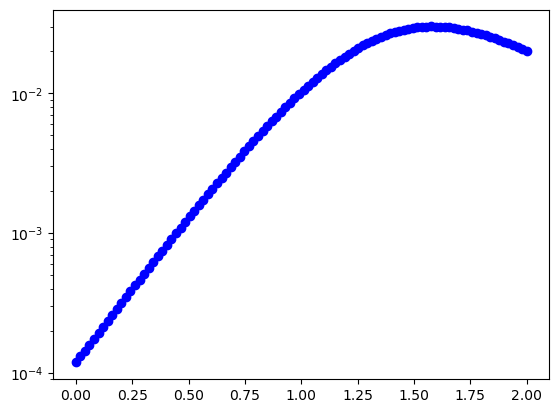

In [79]:
plt.scatter(np.linspace(0, 2, 100), activation_rates, color='blue')  
# plt.scatter(np.linspace(0, 2, 100), falling_coefficients, color='red')
plt.yscale('log')

In [4]:
import numpy as np
beta=1
def toy_unbinding(tau_0, dG, epsilon, beta):
    #dG is like mean, epsilon is like sigma
    return 1 / tau_0 * np.exp(beta * -(dG + 5* np.sqrt(epsilon)))


def D(tau_0, dG, epsilon, beta):
    return 1 / tau_0 * np.exp(beta * -(dG + 3/2 *epsilon)) 


def diffusion_rate_coefficient(tau_0, dG, epsilon, beta=beta, k=1, n_steps=100, n_nucleotides=100):
    diffusion_coefficient = D(tau_0, dG, epsilon, beta)
    # return diffusion_coefficient / (k**2 * (n_steps / n_nucleotides)**2)
    return diffusion_coefficient 


N=3
def generate_transition_matrix(dG_unbind, dG_diffusion, tau_0_diffusion, tau_0_dissociation, epsilon, n_states=N, n_nucleotides=N, rate_absorption=1, beta=1):
    L = np.zeros((N, N))
    # specific_binding_energies = specific_binding_energy(sigma, tau_3d=tau_3d, tau_0=tau_0_dissociation, size=n_states)
    for i in range(N):
        for j in range(N):
            if j == 0 and i == 0:
                L[i, j] -= diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=N, n_nucleotides=N) 
            if j == i and i != 0:
                # nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta)
                L[i, j] -= 2 * diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides) + k_unbinding
            if j == i - 1 or j == i + 1:
                L[i, j] += diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides)
            if i == 0 and i != j:
                # nonspecific_binding_energy = E_ns(sigma, tau_3d=1, tau_0=tau_0, beta=beta)
                k_unbinding = toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta)
                L[i, j] += k_unbinding
                # L[i, j] += diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides)
            if i == N-1 and j == N-1:
                L[i, j] += diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides) - rate_absorption
            if i == 0 and j == N-1:
                L[i, j] += rate_absorption
    return L

# def generate_transition_matrix(dG_unbind, dG_diffusion, tau_0_diffusion, tau_0_dissociation, epsilon, n_states=N, n_nucleotides=N, rate_absorption=1, beta=1):
#     return np.array([
#         [-diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=N, n_nucleotides=N), diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=N, n_nucleotides=N) + toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta), rate_absorption +  toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta)],
#         [diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=N, n_nucleotides=N), -2 * diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides) - toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta), diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides)],
#         [0, diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides), -diffusion_rate_coefficient(tau_0_diffusion, dG_diffusion, epsilon, beta, n_steps=n_states, n_nucleotides=n_nucleotides) - rate_absorption - toy_unbinding(tau_0_dissociation, dG_unbind, epsilon, beta=beta)]
#     ]) 

In [5]:
import matplotlib.pyplot as plt
import mpmath
import numpy as np
N=2
rate_absorption = 0
p3s = []
p2s = []
p1s = []
diffusion_rate_coefficients = []
falling_coefficients = []
for epsilon in np.linspace(-10, 10, 100):
    dG_bind = 0
    dG_diffusion = 0
    tau_0_diffusion = 0.1
    tau_0_dissociation = 0.001
    L = generate_transition_matrix(dG_bind, dG_diffusion, tau_0_diffusion, tau_0_dissociation, epsilon, n_states=N, n_nucleotides=N, rate_absorption=rate_absorption)
    for i in range(N):
        L[N-1, i] = 1
    p = np.zeros(N)
    p[N-1] = 1
    p_ss = mpmath.lu_solve(L,p)
    p3s.append(p_ss[N-1])


/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_14221/782912182.py:5: RuntimeWarning: invalid value encountered in sqrt
  return 1 / tau_0 * np.exp(beta * -(dG + 5* np.sqrt(epsilon)))


/Users/jbwang/miniconda3/envs/proteome/lib/python3.12/site-packages/matplotlib/cbook.py:1398: RuntimeWarning: invalid value encountered in cast
  return np.asarray(x, float)


Text(0.5, 1.0, '$w_{activation}=0.1\\ s^{-1}$')

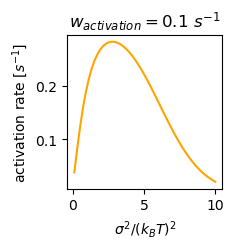

In [6]:
plt.figure(figsize=(2,2))
plt.plot(np.linspace(-10, 10, 100), np.array(p3s) , color='orange') 
# plt.yscale('log') 
plt.xlabel(r'$\sigma^2 / (k_B T)^2$')
plt.ylabel('activation rate [$s^{-1}$]')
plt.title(r'$w_{activation}=0.1\ s^{-1}$')
# plt.xlim(0,20)
# plt.ylim(1e-2, 1)
# plt.scatter(np.linspace(-2, 2, 100), p2s, color='blue')  
# plt.scatter(np.linspace(-2, 2, 100), p1s, color='red')  

# plt.scatter(np.linspace(-0.2, 0.2, 100), [p1s[i] + p2s[i] + p3s[i] for i in range(len(p1s))], color='blue')  


# dynamic catalysis

In [739]:
def dynamic_catalysis_TF(amplitude, midpoint, alpha_i_ii, alpha_ii_i, k_diffusion, k_unbinding, rate_absorption, beta=1):
    dG_diffusion = 0
    dG_unbind = 0
    epsilon_1 = midpoint + amplitude
    epsilon_2 = midpoint - amplitude
    D1 = D(k_diffusion, dG_diffusion, epsilon_1, beta)
    k1 = toy_unbinding(k_unbinding, dG_unbind, epsilon_2, beta=beta)
    D2 = D(k_diffusion, dG_diffusion, epsilon_2, beta)
    k2 = toy_unbinding(k_unbinding, dG_unbind, epsilon_1, beta=beta)
    L = np.array([
        [-D1 - alpha_i_ii, k1 + D1 + rate_absorption, alpha_ii_i, 0],
        [D1, -rate_absorption - D1 - k1 - alpha_i_ii, 0, alpha_ii_i],
        [alpha_i_ii, 0, -D2 - alpha_ii_i, k2 + D2 + rate_absorption],
        [0, alpha_i_ii, D2, -rate_absorption - k2 - D2 - alpha_ii_i]])
    return L

In [740]:
midpoint

np.float64(2.121212121212121)

In [741]:
import matplotlib.pyplot as plt
import mpmath
N=4
rate_absorption = 0.1
p=[]
diffusion_rate_coefficients = []
falling_coefficients = []
max_p3_position = np.where(np.array(p3s) == np.max(p3s))[0]
epsilon = np.linspace(-10, 10, 100)
midpoint = epsilon[int(max_p3_position[0])]
amplitude = 1
frequency_heatmap = np.zeros((100, 100))

for i, alpha_i_ii in enumerate(np.linspace(1e-3, 100, 100)):
    for j, alpha_ii_i in enumerate(np.linspace(1e-3, 100, 100)):
        L = dynamic_catalysis_TF(amplitude, midpoint=midpoint, alpha_i_ii=alpha_i_ii, alpha_ii_i=alpha_ii_i, k_diffusion=tau_0_diffusion, k_unbinding=tau_0_dissociation, rate_absorption=rate_absorption, beta=beta)
        for k in range(N):
            L[N-1, k] = 1
        p = np.zeros(N)
        p[N-1] = 1
        p_ss = mpmath.lu_solve(L,p)
        frequency_heatmap[i,j] = (p_ss[1] + p_ss[3]) / (p3s[int(max_p3_position[0])])


<>:14: SyntaxWarning: invalid escape sequence '\ '
<>:15: SyntaxWarning: invalid escape sequence '\ '
<>:14: SyntaxWarning: invalid escape sequence '\ '
<>:15: SyntaxWarning: invalid escape sequence '\ '
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_9089/2185898598.py:14: SyntaxWarning: invalid escape sequence '\ '
  plt.xlabel('$w_{I,II}\ [s^{-1}]$')
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_9089/2185898598.py:15: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$w_{II,I}\ [s^{-1}]$')


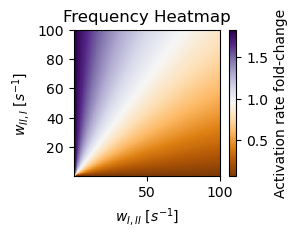

In [757]:
from bokeh.models import LinearColorMapper, ColorBar, BasicTicker, LogColorMapper
from bokeh.palettes import Spectral6, Reds3, brewer
import bokeh
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
cmap = LinearSegmentedColormap.from_list('mycmap', palette)


palette = brewer['PuOr'][11][::-1]
palette = bokeh.palettes.interp_palette(palette, 400)


plt.figure(figsize=(2.4,1.9))
plt.imshow(frequency_heatmap, extent=[1e-3, 100, 1e-3, 100], origin='lower', cmap=cmap)
plt.xlabel('$w_{I,II}\ [s^{-1}]$')
plt.ylabel('$w_{II,I}\ [s^{-1}]$')
plt.title('Frequency Heatmap')
plt.colorbar(label='Activation rate fold-change')
plt.show()

ValueError: x and y must be the same size

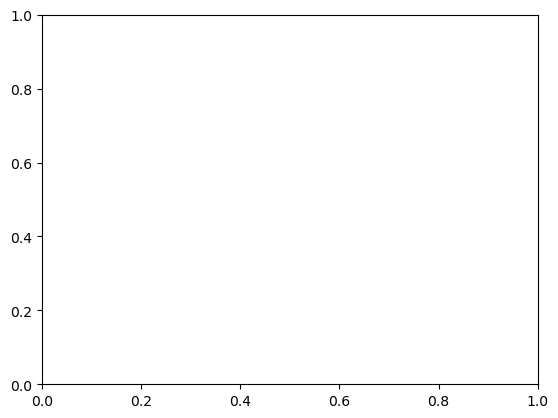

In [728]:
plt.scatter(np.linspace(-10, 10, 100), falling_coefficients, color='red')
plt.scatter(np.linspace(-10, 10, 100), diffusion_rate_coefficients, color='green')

In [ ]:
def three_state_model(k_bind_1, k_unbind_1, k_bind_2, k_unbind_2, D, rate_absorption):
    L = np.array([
        [-D - k_unbind_1, D + rate_absorption, k_bind_1],
        [D, -rate_absorption - D - k_unbind_2, k_bind_2],
        [k_unbind_1, k_unbind_2, - 2 * k_bind_1]
    ]) 
    return L

def toy_unbinding(tau_0, dG, epsilon, beta):
    #dG is like mean, epsilon is like sigma
    
    return 1 / tau_0 * np.exp(beta * -(dG + epsilon))


def D(tau_0, dG, epsilon, beta):
    return 1 / tau_0 * np.exp(beta * -(dG + 3 / 2 *epsilon)) 

In [558]:
import matplotlib.pyplot as plt
import mpmath
N=3
rate_absorption = 1e-5
p3s = []
p2s = []
p1s = []
diffusion_rate_coefficients = []
falling_coefficients = []
for epsilon in np.linspace(-10, 10, 100):
    dG_bind = 0
    dG_diffusion = 0
    tau_0_diffusion_1 = 1
    tau_0_dissociation_1 = 1
    tau_0_dissociation_2 = 1
    
    k_unbind_1 = toy_unbinding(1/ tau_0_dissociation_1, dG_bind, epsilon, beta=beta)
    k_unbind_2 = toy_unbinding(1/ tau_0_dissociation_2, dG_bind, epsilon, beta=beta)
    diffusion_coefficient = diffusion_rate_coefficient(tau_0_diffusion_1, dG_diffusion, epsilon, beta=beta, n_steps=N, n_nucleotides=N)
    L = three_state_model(1 / tau_0_dissociation_1, k_unbind_1, 1 / tau_0_dissociation_2, k_unbind_2, diffusion_coefficient, rate_absorption)
    for i in range(N):
        L[N-1, i] = 1
    p = np.zeros(N)
    p[N-1] = 1
    p_ss = mpmath.lu_solve(L,p)
    p3s.append(p_ss[1])


Text(0.5, 1.0, 'rates of activation at $w_{activation}=0.1$')

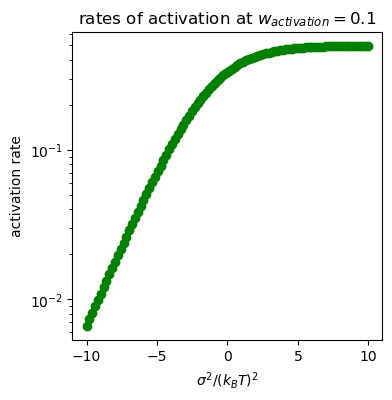

In [559]:
plt.figure(figsize=(4,4))
plt.scatter(np.linspace(-10, 10, 100), p3s, color='green') 
plt.yscale('log') 
plt.xlabel(r'$\sigma^2 / (k_B T)^2$')
plt.ylabel('activation rate')
plt.title(r'rates of activation at $w_{activation}=0.1$')
# plt.xlim(0,20)
# plt.ylim(1e-2, 1)
# plt.scatter(np.linspace(-2, 2, 100), p2s, color='blue')  
# plt.scatter(np.linspace(-2, 2, 100), p1s, color='red')  

# plt.scatter(np.linspace(-0.2, 0.2, 100), [p1s[i] + p2s[i] + p3s[i] for i in range(len(p1s))], color='blue')  
